In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [76]:
######build the dataset

#set a blocksize i.e. how many characters will be considered at a time
blocksize = 4

#create an X and Y mapping arrays
X, Y = [],[]

#for every word

for w in words:
    #print it 
    #print(w)
    
    #create a context list of length blocksize
    context = [0]*blocksize

    #for every ch in the word (plus '.' for end char)
    for ch in w + '.':
        #get the index of the char
        ix = stoi[ch]
        #add the context that produced this char to X list
        X.append(context)
        
        #add the output (ix) to the Y list
        Y.append(ix)
        
        #print a thing that summarizes what you just did for legibility
        #print(''.join(itos[i] for i in context), '--->', itos[ix])
        
        #crop and append the context
        context = context[1:]+[ix]

#set X and Y to torch tensors
X = torch.tensor(X)
Y = torch.tensor(Y)

In [77]:
######build the dataset WITH SPLITS
def build_dataset(words):
    #set a blocksize i.e. how many characters will be considered at a time
    blocksize = 4
    
    #create an X and Y mapping arrays
    X, Y = [],[]
    
    #for every word
    
    for w in words:
        #print it 
        #print(w)
        
        #create a context list of length blocksize
        context = [0]*blocksize
    
        #for every ch in the word (plus '.' for end char)
        for ch in w + '.':
            #get the index of the char
            ix = stoi[ch]
            #add the context that produced this char to X list
            X.append(context)
            
            #add the output (ix) to the Y list
            Y.append(ix)
            
            #print a thing that summarizes what you just did for legibility
            #print(''.join(itos[i] for i in context), '--->', itos[ix])
            
            #crop and append the context
            context = context[1:]+[ix]
        #set X and Y to torch tensors
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

#split the dataset
import random
random.seed(42)
random.shuffle(words)

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))
Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])



In [90]:
#MLP init
features = 10
neuron_count = 200


g = torch.Generator().manual_seed(2147483647)

C = torch.randn(27, features,  generator=g)
W1 = torch.randn((features*blocksize, neuron_count),  generator=g)
b1 = torch.randn(neuron_count, generator=g)
W2 = torch.randn((neuron_count, 27),  generator=g)
b2 = torch.randn(27,  generator=g)
params = [C, W1, b1, W2, b2]

for p in params:
    p.requires_grad = True

In [91]:
sum(p.nelement() for p in params)

13897

In [92]:
stepi = []
lri = []
lossi = []
steps = 100000

for i in range(steps): 
    #minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (64,))
    #forward pass
    emb = C[Xtr[ix]] #(examples, 3, 2) #embed inputs in feature vectors 
    h = torch.tanh(emb.view(-1, features*blocksize) @ W1 + b1) #use view to reshape 
    logits = h @ W2 + b2 # raw NN outputs ranging +- around 0
    loss = F.cross_entropy(logits, Ytr[ix]) #softmax classification of logits, forward and backward much more efficient, fewer bugs

    
    #backward pass
    for p in params:
        p.grad = None
    
    loss.backward()

    lr = 0.1
    if i > steps*0.75:
        lr = 0.01
        
    for p in params:
        p.data += -lr*p.grad

    # #track stats
    # lri.append(lre[i])
    lossi.append(loss.log10().item())
    stepi.append(i)

print(loss.item())

2.215733289718628


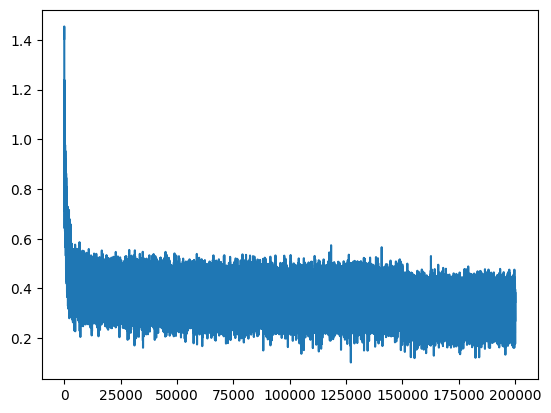

In [93]:
plt.plot(stepi, lossi)

In [94]:
#dev loss
emb = C[Xtr] #(examples, 3, 2) #embed inputs in feature vectors 
h = torch.tanh(emb.view(-1, features*blocksize) @ W1 + b1) #use view to reshape [32, 3, 2] ----> [32, 6] for matmul 
logits = h @ W2 + b2 # raw NN outputs ranging +- around 0
loss = F.cross_entropy(logits, Ytr) #softmax classification of logits, forward and backward much more efficient, fewer bugs
loss.item()

2.126225233078003

In [95]:
#dev loss
emb = C[Xdev] #(examples, 3, 2) #embed inputs in feature vectors 
h = torch.tanh(emb.view(-1, features*blocksize) @ W1 + b1) #use view to reshape [32, 3, 2] ----> [32, 6] for matmul 
logits = h @ W2 + b2 # raw NN outputs ranging +- around 0
loss = F.cross_entropy(logits, Ydev) #softmax classification of logits, forward and backward much more efficient, fewer bugs
loss.item()

2.1682775020599365

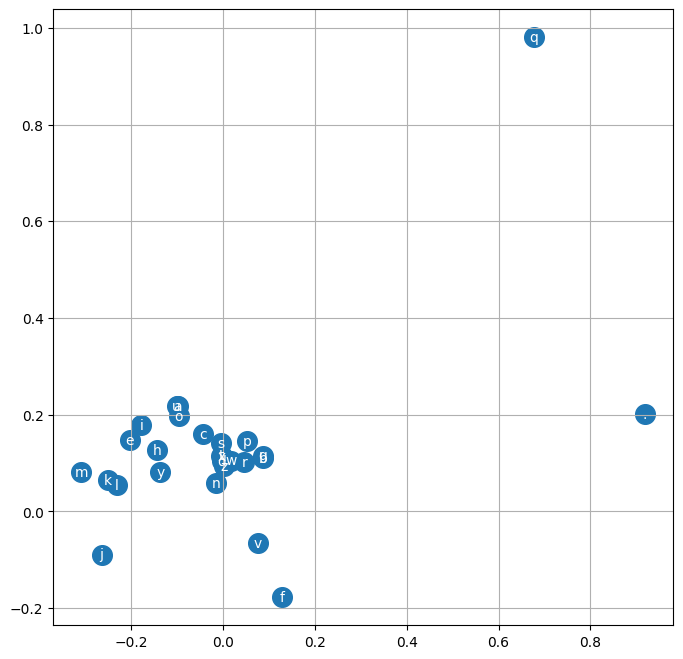

In [68]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
    plt.grid('minor')
    